# Training-only exploration and simple baselines

This notebook asks what a useful forecast must beat. It summarizes only the training targets and scores three simple forecasts on 2017 validation hours. The final test partition is not loaded.

**Source:** Hogue (2019), [Metro Interstate Traffic Volume](https://doi.org/10.24432/C5X60B), UCI Machine Learning Repository, CC BY 4.0. The local hourly table is derived from the attributed source; see the [data card](../docs/DATA_CARD.md).

## Context & methods

The target is reported vehicles per source-clock hour. Training ends before 2017; validation covers 2017. At forecast issue time (the start of hour *t*), the contract permits history only through *t−2*. The seasonal baseline therefore uses the exact observed count at *t−168* hours, when available. No weather, quality flags, random split, or final-test values are used.

All baseline errors use the same validation hours: actual targets with a measured target at the same hour one week earlier. This gives a fair comparison and makes seasonal-data coverage visible. MAE is typical absolute error; RMSE gives larger misses extra weight.

In [1]:
from html import escape
from IPython.display import HTML, SVG, display
from pathlib import Path
import sys

project = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project / 'src'))
from trafficpulse.baselines import (
    analyze,
    hourly_profile_chart_svg,
    read_hourly,
    score_chart_svg,
)


def render_table(headers, rows):
    header_cells = ''.join(
        f"<th>{escape(str(header))}</th>" for header in headers
    )
    body_rows = ''.join(
        '<tr>' + ''.join(f"<td>{escape(str(value))}</td>" for value in row) + '</tr>'
        for row in rows
    )
    return HTML(f'<table><thead><tr>{header_cells}</tr></thead><tbody>{body_rows}</tbody></table>')


train = read_hourly(project / 'data/processed/train.csv')
validation = read_hourly(project / 'data/processed/validation.csv')
hourly = train + validation
results = analyze(hourly)
print(
    f'Loaded {len(train):,} training slots and '
    f'{len(validation):,} validation slots; test data were not opened.'
)

Loaded 37,239 training slots and 8,760 validation slots; test data were not opened.


## Training data

The summary below uses observed training targets only. The chart shows the mean target by hour of day; it is descriptive, not a fitted predictive model. Source-clock timing is retained because the source timezone and daylight-saving interpretation remain unresolved.

Training-only measure,Vehicles/hour
Mean,"3,252.5"
Median,"3,339.0"
Standard Deviation,"1,987.1"
P10,426.0
P90,"5,822.0"
Min,0.0
Max,"7,260.0"
Observed training hours,"25,329"


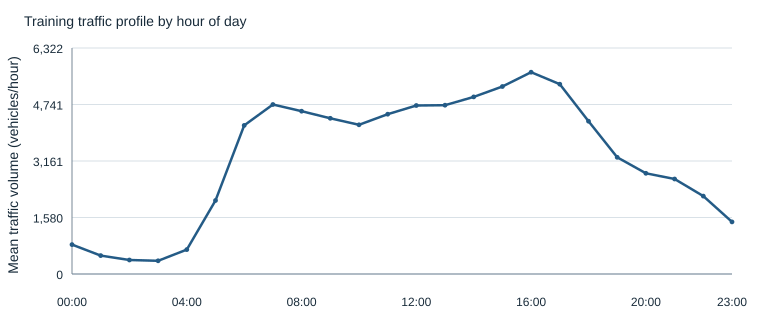

In [2]:
distribution = results['training']['traffic_volume_distribution']
summary_rows = [
    (name.replace('_', ' ').title(), f'{value:,.1f}')
    for name, value in distribution.items()
    if isinstance(value, (int, float)) and name != 'count'
]
summary_rows.append(('Observed training hours', f"{distribution['count']:,}"))
display(render_table(['Training-only measure', 'Vehicles/hour'], summary_rows))
display(SVG(hourly_profile_chart_svg(results)))

## Validation results

The global mean is a simple reference. The weekday-hour mean uses the matching group from training, with the training global mean as a documented fallback. Same-hour-last-week copies the allowed lag only when it is actually observed; it does not fill missing history. Scores below use the shared eligible validation population.

Baseline,MAE (vehicles/hour),RMSE (vehicles/hour),Mean error (vehicles/hour),Hours
Training Global Mean,"1,742.8","1,985.1",-124.5,"8,667"
Training Hour Of Week Mean,279.1,461.7,-106.1,"8,667"
Same Hour Last Week,302.6,564.2,3.1,"8,667"


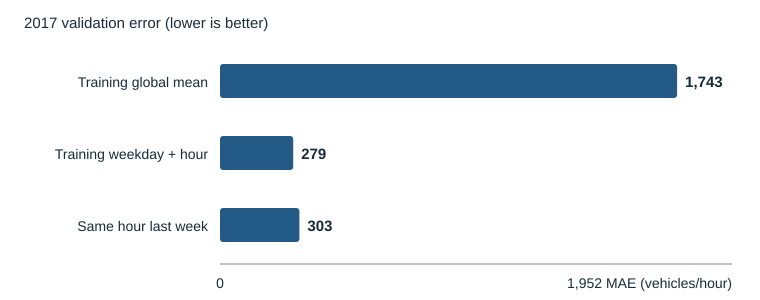

In [3]:
validation_result = results['validation']
coverage_text = (
    f"<p><b>Shared comparison:</b> "
    f"{validation_result['shared_cohort_n']:,} of "
    f"{validation_result['observed_targets']:,} observed validation targets "
    f"({validation_result['seasonal_lag_coverage_of_observed_targets']:.1%}) "
    'have observed same-hour-last-week history.</p>'
)
display(HTML(coverage_text))
score_rows = [
    (
        name.replace('_', ' ').title(),
        f"{score['mae_vehicles_per_hour']:,.1f}",
        f"{score['rmse_vehicles_per_hour']:,.1f}",
        f"{score['mean_error_vehicles_per_hour']:,.1f}",
        f"{score['n']:,}",
    )
    for name, score in validation_result['baselines'].items()
]
display(render_table(
    ['Baseline', 'MAE (vehicles/hour)', 'RMSE (vehicles/hour)',
     'Mean error (vehicles/hour)', 'Hours'],
    score_rows,
))
display(SVG(score_chart_svg(results)))

## Takeaways

Compare model errors with the table, not just the chart. The weekday-hour baseline can reflect a recurring weekly pattern that one overall average cannot. The seasonal baseline tests whether repeating exactly last week's value is useful; a fixed historical average can still be steadier. These are reference points, not proof that any later model will generalize.

The common cohort omits observed validation hours whose one-week lag is missing. The score describes this covered subset. It does not describe performance on missing targets or guarantee performance under a different reporting-delay assumption. The final 2018+ holdout remains sealed for one later evaluation after model choices are frozen.

In [4]:
assert all(
    score['n'] == validation_result['shared_cohort_n']
    for score in validation_result['baselines'].values()
)
assert results['methodology']['final_test_read'] is False
assert all(row['split'] in {'train', 'validation'} for row in hourly)
print('Checks passed: shared rows, training-only fit, and no final-test input.')

Checks passed: shared rows, training-only fit, and no final-test input.
